# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression. 

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept). 
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already. 
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Kaitlin Luu, Natalie Schweickert, James Torgerson"

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below tasks.

For BinaryMLP the cost function is Binary Cross-Entropy. For MulticlassMLP the cost function is Categorical Cross-Entropy. For RegressionMLP the cost function is Mean Squared Error.

- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.

For BinaryMLP there is 1 output unit with a sigmoid activation. For MulticlassMLP there is 1 output unit per class (so $l$ units for $l$ classes) with a softmax activation. For RegressionMLP there is 1 output unit with a linear (identity) activation, since the prediction is just the weighted sum of the inputs plus the bias.

- Why it is important to standardize the data before training each model.

It is important to standardize the data before training each model because features on different scales will produce uneven gradients. For instance, the model may have a much larger impact on features with large values compared to features with small values. Therefore, training would be ineffective if we used a single learning rate on all of the data. Making the mean 0 and standard deviation 1 also ensures that the random weight initialization for the model works since it assumes that everything is of similar scale. Additionally, standardizing keeps the numbers in a range where RelU and Tanh work properly. This ensures that the differences in the results for reflect the difference in activation function rather a difference than scaling.

- How you could detect overfitting when training your models.

Primarily, the way we detect overfitting is by comparing how our model performs on training data versus our test/holdout data. If our model performs well on the former but not on the latter, then we know our model is overfitting. For MLP and other neural network models, we can also compare our training loss versus our test loss. As we train our data, if our training loss continues to decrease while our test loss plateaus, then we are overfitting. Lastly, we can look at our model to see if we are likely overfitting - if we have a large number of parameters relative to our number of observations, then we are likely overfitting.

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [6]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [7]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [8]:
# 80/20 split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234, stratify=y)

In [12]:
# standardize on train set
scaler = StandardScaler().fit(X_train)

# apply to train and test sets
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

In [13]:
# convert to PyTorch tensors

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

In [ ]:
# implement BinaryMLP

class BinaryMLP:
    def __init__(self, n_features, n_hidden, n_layers=1, activation="relu", seed=1234):
        assert n_layers in (1, 2), "n_layers must be 1 or 2"
        assert activation in ("relu", "tanh")
        self.n_layers = n_layers
        self.activation = activation
        g = torch.Generator().manual_seed(seed)

        def init(fan_in, fan_out):
            # initialize weights randomly and biases as zeros
            std = (2.0 / fan_in) ** 0.5 if activation == "relu" else (1.0 / fan_in) ** 0.5
            W = (torch.randn(fan_in, fan_out, generator=g) * std).requires_grad_()
            b = torch.zeros(1, fan_out, requires_grad=True)
            return W, b

        # initialize both hidden layers
        self.W1, self.b1 = init(n_features, n_hidden)
        if n_layers == 2:
            self.W2, self.b2 = init(n_hidden, n_hidden)
        self.Wo, self.bo = init(n_hidden, 1)

        # store weights and biases to update during training
        self.params = [self.W1, self.b1, self.Wo, self.bo]
        if n_layers == 2:
            self.params += [self.W2, self.b2]


    def _act(self, z):
        return torch.relu(z) if self.activation == "relu" else torch.tanh(z)

    def forward(self, X):
        h = self._act(X @ self.W1 + self.b1)
        if self.n_layers == 2:
            h = self._act(h @ self.W2 + self.b2)
        return torch.sigmoid(h @ self.Wo + self.bo)

    def cost(self, y_true, p, eps=1e-12):
        # binary cross-entropy (eps avoids log(0))
        return -(y_true * torch.log(p + eps) + (1 - y_true) * torch.log(1 - p + eps)).mean()

    def predict(self, X, threshold=0.5):
        with torch.no_grad():
            return (self.forward(X) >= threshold).float()

    def fit(self, X, y, epochs=200, lr=0.05, batch_size=32, X_val=None, y_val=None, seed=1234):
        g = torch.Generator().manual_seed(seed)
        n = X.shape[0]
        self.history = {"train_cost": [], "val_cost": []}

        for epoch in range(epochs):
            perm = torch.randperm(n, generator=g)

            # process training data in smaller batches
            for start in range(0, n, batch_size):
                idx = perm[start:start + batch_size]
                loss = self.cost(y[idx], self.forward(X[idx]))

                for p in self.params:
                    p.grad = None
                loss.backward()

                with torch.no_grad():
                    for p in self.params:
                        p -= lr * p.grad

            # get training and validation loss for each epoch
            with torch.no_grad():
                self.history["train_cost"].append(self.cost(y, self.forward(X)).item())
                if X_val is not None:
                    self.history["val_cost"].append(self.cost(y_val, self.forward(X_val)).item())
        return self

# calculate accuracy of classifications
def accuracy_b(y_true, y_pred):
    return (y_true == y_pred).float().mean().item()
    

Train acc:   0.9599999785423279
Holdout acc: 0.9850000143051147


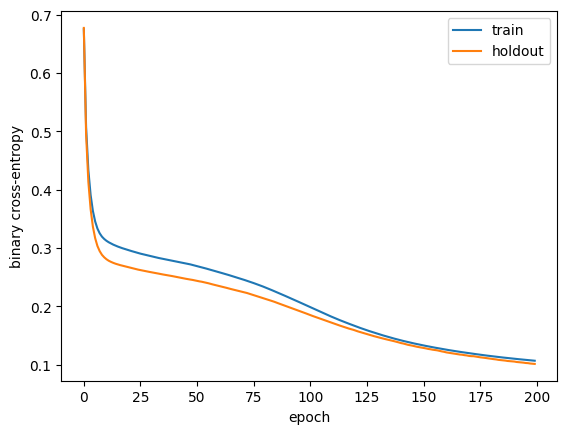

In [ ]:
# sanity check
m = BinaryMLP(2, 8, n_layers=1, activation="relu")
m.fit(X_train_t, y_train_t, epochs=200, lr=0.05, X_val=X_test_t, y_val=y_test_t)

# print accuracy on training and holdout sets
print("Train acc:  ", accuracy_b(y_train_t, m.predict(X_train_t)))
print("Holdout acc:", accuracy_b(y_test_t, m.predict(X_test_t)))

# plot loss across epochs
plt.plot(m.history["train_cost"], label="train")
plt.plot(m.history["val_cost"], label="holdout")
plt.xlabel("epoch"); plt.ylabel("binary cross-entropy"); plt.legend(); plt.show()

In [19]:
# compare different neural network configurations

results = []

# test relu and tanh activation functions
for activation in ["relu", "tanh"]:
    for n_hidden in [2, 4, 8, 16, 32]:
        for n_layers in [1, 2]:

            # make neural network and train model
            model = BinaryMLP(2, n_hidden, n_layers=n_layers, activation=activation)
            model.fit(X_train_t, y_train_t, epochs=200, lr=0.05,
                      X_val=X_test_t, y_val=y_test_t)
            results.append({
                "activation": activation,
                "hidden_layers": n_layers,
                "hidden_units": n_hidden,
                "train_acc": accuracy_b(y_train_t, model.predict(X_train_t)),
                "holdout_acc": accuracy_b(y_test_t, model.predict(X_test_t)),
                "train_cost": model.history["train_cost"][-1],
                "holdout_cost": model.history["val_cost"][-1],
            })

# make dataframe with results that sorts by model configuration 
results_df = (pd.DataFrame(results)
                .sort_values(["activation", "hidden_layers", "hidden_units"])
                .reset_index(drop=True)
                .round(4))
results_df

,activation,hidden_layers,hidden_units,train_acc,holdout_acc,train_cost,holdout_cost
0,relu,1,2,0.8737,0.855,0.2926,0.2591
1,relu,1,4,0.9600,0.990,0.0917,0.0787
2,relu,1,8,0.9600,0.985,0.1070,0.1015
3,relu,1,16,0.9663,0.995,0.0871,0.0811
4,relu,1,32,0.9688,0.990,0.0850,0.0797
5,relu,2,2,0.8763,0.910,0.2596,0.2111
6,relu,2,4,0.9750,0.985,0.0638,0.0811
7,relu,2,8,0.9750,0.980,0.0638,0.0829
8,relu,2,16,0.9800,0.985,0.0565,0.0767
9,relu,2,32,0.9775,0.985,0.0563,0.0732


**Reflection:**

1. How does the number of hidden units affect performance?

As the number of hidden units increased, performance generally improved, producing high accuracy and lower loss. For instance, for ReLU and one hidden layer, holdout accuracy increased from 0.855 to 0.99 and loss decreased when hidden units was changed from 2 to 4. But eventually, the improvements in performance would become smaller as the number of units continued to increase. This shows that increasing number of hidden units may only be beneficial up to a certain point. 

2. What changes when using two layers instead of one?

When it changed to two hidden layers, the performance also improved because it allowed the model to learn more complex patterns. For instance, for ReLU and 4 hidden units, adding another layer raised training accuracy from 0.96 to 0.975 and lowered loss. However, the holdout accuracy decreased slightly, going from 0.99 to 0.985, which indicates that adding another layer does not always improve the model's ability to generalize. 

3. How does the activation function (ReLU vs. Tanh) influence results?

Overall, ReLU performed better than Tanh for smaller networks with fewer hidden units and layers. For some of the larger networks with more hidden units and layers, Tanh performed better. Sometimes, they had the same or very similar accuracies, but different loss values. 

## 3. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$-\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [2]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3, 
                           n_clusters_per_class=1, 
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

In [3]:
# imports
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import matplotlib.pyplot as plt

In [4]:
# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234, stratify=y)

In [5]:
# standardize on train set
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# one hot encode
ohe = OneHotEncoder(sparse_output=False).fit(y_train.reshape(-1, 1))
Y_train_oh = ohe.transform(y_train.reshape(-1, 1))
Y_test_oh = ohe.transform(y_test.reshape(-1, 1))

In [6]:

# convert to PyTorch tensors
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
Y_train_t = torch.tensor(Y_train_oh, dtype=torch.float32)
Y_test_t = torch.tensor(Y_test_oh, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

In [10]:
# MultiClassMLP
class MultiClassMLP:
    def __init__(self, n_features, n_hidden, n_classes, n_layers=1,
                 activation="relu", seed=1234):
        assert n_layers in (1, 2), "n_layers must be 1 or 2"
        assert activation in ("relu", "tanh")
        self.n_layers = n_layers
        self.activation = activation
        g = torch.Generator().manual_seed(seed)
 
        def init(fan_in, fan_out):
            std = (2.0 / fan_in) ** 0.5 if activation == "relu" else (1.0 / fan_in) ** 0.5
            W = (torch.randn(fan_in, fan_out, generator=g) * std).requires_grad_()
            b = torch.zeros(1, fan_out, requires_grad=True)
            return W, b
 
        self.W1, self.b1 = init(n_features, n_hidden)
        if n_layers == 2:
            self.W2, self.b2 = init(n_hidden, n_hidden) # extra hidden layer      
        self.Wo, self.bo = init(n_hidden, n_classes)       
 
        self.params = [self.W1, self.b1, self.Wo, self.bo]
        if n_layers == 2:
            self.params += [self.W2, self.b2]
 
    def _act(self, z):
        return torch.relu(z) if self.activation == "relu" else torch.tanh(z)
 
    def forward(self, X):
        h = self._act(X @ self.W1 + self.b1)
        if self.n_layers == 2:
            h = self._act(h @ self.W2 + self.b2)
        logits = h @ self.Wo + self.bo
        return F.softmax(logits, dim=1)               
 
    def cost(self, Y_onehot, probs, eps=1e-12):
        return -(Y_onehot * torch.log(probs + eps)).sum(dim=1).mean()
 
    def predict(self, X):
        with torch.no_grad():
            return torch.argmax(self.forward(X), dim=1)
 
    def fit(self, X, Y_onehot, epochs=200, lr=0.05, batch_size=32,
            X_val=None, Y_val=None, seed=1234):
        g = torch.Generator().manual_seed(seed)
        n = X.shape[0]
        self.history = {"train_cost": [], "val_cost": []}
 
        for epoch in range(epochs):
            perm = torch.randperm(n, generator=g)             
            for start in range(0, n, batch_size):
                idx = perm[start:start + batch_size]
                probs = self.forward(X[idx])
                loss = self.cost(Y_onehot[idx], probs)
 
                for p in self.params:                      
                    p.grad = None
                loss.backward()                               
 
                with torch.no_grad():                        
                    for p in self.params:
                        p -= lr * p.grad
 
            with torch.no_grad():
                self.history["train_cost"].append(self.cost(Y_onehot, self.forward(X)).item())
                if X_val is not None:
                    self.history["val_cost"].append(self.cost(Y_val, self.forward(X_val)).item())
        return self

In [11]:
# accuracy function
def accuracy(y_true, y_pred):
    return (y_true == y_pred).float().mean().item()

Train acc:   0.8125
Holdout acc: 0.8050000071525574


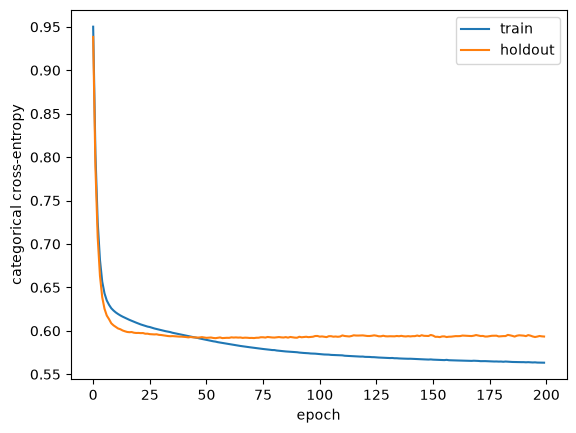

In [12]:
# check
m = MultiClassMLP(2, 8, 3, n_layers=1, activation="relu")
m.fit(X_train_t, Y_train_t, epochs=200, lr=0.05, X_val=X_test_t, Y_val=Y_test_t)
print("Train acc:  ", accuracy(y_train_t, m.predict(X_train_t)))
print("Holdout acc:", accuracy(y_test_t, m.predict(X_test_t)))
 
plt.plot(m.history["train_cost"], label="train")
plt.plot(m.history["val_cost"], label="holdout")
plt.xlabel("epoch"); plt.ylabel("categorical cross-entropy"); plt.legend(); plt.show()

In [15]:
# results
results_df = (pd.DataFrame(results)
              .sort_values(["activation", "hidden_layers", "hidden_units"])
              .reset_index(drop=True)
              .round(4))
results_df

,activation,hidden_layers,hidden_units,train_acc,holdout_acc,train_cost,holdout_cost
0,relu,1,2,0.7950,0.790,0.5976,0.6161
1,relu,1,4,0.8100,0.800,0.5747,0.5999
2,relu,1,8,0.8125,0.805,0.5633,0.5934
3,relu,1,16,0.8138,0.795,0.5516,0.6138
4,relu,1,32,0.8125,0.795,0.5487,0.6122
5,relu,2,2,0.7788,0.760,0.7235,0.7669
6,relu,2,4,0.8150,0.800,0.5537,0.5917
7,relu,2,8,0.8163,0.795,0.5480,0.6202
8,relu,2,16,0.8125,0.795,0.5401,0.6256
9,relu,2,32,0.8200,0.795,0.5317,0.6274


Write Up: 
1. How does the number of hidden units affect performance?

With 2 units, ReLU 1-layer has the highest training cost of its group (0.598) and the lowest holdout accuracy (0.790). Tanh 1-layer is similar (0.785).
Gains stop at about 4-8 units. Holdout accuracy peaks at 0.800-0.805 there, and holdout cost is lowest (ReLU 0.593 at 8 units, Tanh 0.582 at 4 units).
More units only fit the noise. Training cost keeps falling (ReLU 1-layer: 0.598 → 0.549 from 2 to 32 units), but holdout cost rises after the best size (ReLU 0.593 → 0.612, Tanh 0.582 → 0.609). Holdout accuracy doesn’t improve either, ending at 0.795.



2. What changes when using two layers instead of one?

Training fit is slightly better when using two layers instead of 1. Training cost is lower at most sizes, e.g. ReLU 32 units: 0.532 (2 layers) vs. 0.549 (1 layer).
Holdout performance is not better. Holdout accuracy is within about 0.01 at nearly every size, and holdout cost is equal or worse (ReLU 16 units: 0.626 vs. 0.614). The extra layer adds capacity that only fits noise.
ReLU with 2 units is the outlier. Two layers gives 0.760 holdout accuracy and a training cost of 0.724, so it underfits (a very narrow bottleneck, and ReLU units can go inactive). Tanh with the same shape is fine (0.795).


3. How does the activation function (ReLU vs. Tanh) influence results?

Accuracy is essentially the same. Both reach about 0.79-0.805 on holdout. The differences are 1-3 observations out of 200, which is within noise.
Tanh is a bit steadier at small sizes. Tanh 2-layer with 2 units reaches 0.795, while ReLU collapses to 0.760.
Tanh has the lowest holdout costs. Its best is 0.582, vs. 0.592 for ReLU.

## 4: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [31]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

In [32]:
# 1 - Implementation - Regression Task
import torch

class RegressionMLP(object):

    def __init__(self, input_dim, hidden_dim1, hidden_dim2=None, learning_rate=0.001, activation=torch.relu, seed=1234):

        self.learning_rate = learning_rate
        self.hidden_dim2 = hidden_dim2 
        self.activation = activation # so we can perform model training/evaluation on tanh v. relu
        g = torch.Generator().manual_seed(seed) #seed for reproducibility

        # as w/ previous functions, scale by fan in - was having issues w/ signal blowing up :'(
        gain = 2.0 if activation is torch.relu else 1.0
        def init(fan_in, fan_out):
            W = (torch.randn(fan_in, fan_out, generator=g) * (gain / fan_in) ** 0.5).requires_grad_()
            b = torch.zeros(fan_out, requires_grad=True)
            return W, b

        self.W_1, self.b_1 = init(input_dim, hidden_dim1)

        # 1 hidden layer option
        if hidden_dim2 == None:
            self.W_2, self.b_2 = init(hidden_dim1, 1)
            self.params = [self.W_1, self.b_1, self.W_2, self.b_2]

        # 2 hidden layer option
        else:
            self.W_2, self.b_2 = init(hidden_dim1, hidden_dim2)
            self.W_3, self.b_3 = init(hidden_dim2, 1)
            self.params = [self.W_1, self.b_1, self.W_2, self.b_2, self.W_3, self.b_3]

    def forward(self, X):

        # 1 hidden layer option
        if self.hidden_dim2 == None:
            h = self.activation(torch.matmul(X, self.W_1) + self.b_1) # implements activation(X @ W_1 + b1) --> linear regression 
            out = torch.matmul(h, self.W_2) + self.b_2 # implements h @ W_2 + b2

        # 2 hidden layer option
        else:
            h1 = self.activation(torch.matmul(X, self.W_1) + self.b_1) # implements activation(X @ W_1 + b1) 
            h2 = self.activation(torch.matmul(h1, self.W_2) + self.b_2) # implements activation(h1 @ W_2 +b2)
            out = torch.matmul(h2, self.W_3) + self.b_3 # implements h @ W_3 + b3
            
        return out.squeeze(-1) # shape (n,) so it matches y !!!

    def cost(self, y_pred, y_true):
        # cost function for linear regression is MSE
        return ((y_pred - y_true) ** 2).mean()

    def fit(self, X, y, n_epochs=100, batch_size=32, X_val=None, y_val=None, seed=1234):
        g = torch.Generator().manual_seed(seed)
        n = X.shape[0]

        self.history = {"train_cost": [], "val_cost": []} # initialize empty dictionary so we can check cost w/ sanity check later

        for epoch in range(n_epochs):

            perm = torch.randperm(n, generator=g)

            for start in range(0, n, batch_size): # initially i had this as for ii in randomperm: (etc) like in in-class code, but that led to a really, really long training time... 
                ii = perm[start:start + batch_size]
                x_batch, y_batch = X[ii], y[ii]

                # forward
                y_pred = self.forward(x_batch)

                # cost
                loss = self.cost(y_pred, y_batch)

                # backward pass
                for p in self.params: 
                    # this is kind-of equivalent to our in-class code zero gradients step
                    # but because backward() accumulates gradients into .grad it needs to be cleared before each step
                    # and this is more practical than having a separate block for zero gradients
                    # and matches what group mates have done for other sections :) 
                    p.grad = None 
                loss.backward()

                with torch.no_grad(): # manual SGD
                    # this is equivalent to listing out each parameter (e.g. self.W_1 -= self.learning_rate * self.W_1.grad) as we do in original class code
                    # but using this structure avoids additional 'if' statement for 2 hidden layers option + requires fewer lines of code
                    for p in self.params:
                        p -= self.learning_rate * p.grad

            # record full-dataset cost at the end of each epoch for sanity check visualization
            with torch.no_grad():
                self.history["train_cost"].append(self.cost(self.forward(X), y).item())
                if X_val is not None:
                    self.history["val_cost"].append(self.cost(self.forward(X_val), y_val).item())
        return self


    def predict(self, X):
        with torch.no_grad():
            return self.forward(X)

In [42]:
# 2 - Data Preparation - Regression Task

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## split into training data and holdout
X_train, X_holdout, y_train, y_holdout = train_test_split(X, y, test_size=0.2, random_state=804) 

## standardize 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_holdout_scaled = scaler.transform(X_holdout) # standardize according to scaler fit to training data

### was having issues w/ exploding gradients so will also standardize y 
### this is also addressed by the addition of fan-out scaling in __init__ but wanted to have both just in case :)
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).ravel() #.ravel() is needed to return it to correct shape 
y_holdout_scaled = y_scaler.transform(y_holdout.reshape(-1, 1)).ravel()

# convert to tensor
X_train = torch.from_numpy(X_train_scaled).float()
X_holdout = torch.from_numpy(X_holdout_scaled).float()

y_train = torch.from_numpy(y_train_scaled).float()
y_holdout = torch.from_numpy(y_holdout_scaled).float()

Train MSE:   0.5130937695503235
Holdout MSE: 0.5221683382987976


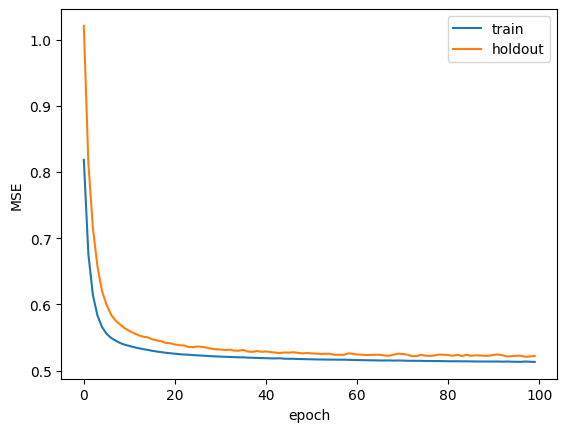

Holdout RMSE (original units): 74.49885


In [43]:
import matplotlib.pyplot as plt

def mse(y_true, y_pred):
    return ((y_pred.squeeze(-1) - y_true) ** 2).mean().item()

# sanity check
m = RegressionMLP(2, 8, learning_rate=0.01, activation=torch.relu)
m.fit(X_train, y_train, n_epochs=100, X_val=X_holdout, y_val=y_holdout)

# MSE on standardized scale
print("Train MSE:  ", mse(y_train, m.predict(X_train)))
print("Holdout MSE:", mse(y_holdout, m.predict(X_holdout)))

# plot loss across epochs
plt.plot(m.history["train_cost"], label="train")
plt.plot(m.history["val_cost"], label="holdout")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

#b/c i standardized y, we have to convert it back to original units so that it's interpretable against our noise=75
pred_orig = y_scaler.inverse_transform(m.predict(X_holdout).numpy().reshape(-1, 1)).ravel()
y_true_orig = y_scaler.inverse_transform(y_holdout.numpy().reshape(-1, 1)).ravel()
print("Holdout RMSE (original units):", ((pred_orig - y_true_orig) ** 2).mean() ** 0.5)

In [44]:
# compare different neural network configurations (using same structure as prev tasks)

import pandas as pd

activations = {"relu": torch.relu, "tanh": torch.tanh}
results = []

for act_name, act_fn in activations.items():
    for n_hidden in [2, 4, 8, 16, 32]:
        for n_layers in [1, 2]:

            model = RegressionMLP(
                input_dim=X_train.shape[1],
                hidden_dim1=n_hidden,
                hidden_dim2=n_hidden if n_layers == 2 else None,
                learning_rate=0.01,
                activation=act_fn,
            )

            model.fit(X_train, y_train, n_epochs=100,
                      X_val=X_holdout, y_val=y_holdout)

            results.append({
                "activation": act_name,
                "hidden_layers": n_layers,
                "hidden_units": n_hidden,
                "train_mse": model.history["train_cost"][-1],
                "holdout_mse": model.history["val_cost"][-1],
            })

results_df = (pd.DataFrame(results)
                .sort_values(["activation", "hidden_layers", "hidden_units"])
                .reset_index(drop=True)
                .round(4))
results_df

,activation,hidden_layers,hidden_units,train_mse,holdout_mse
0,relu,1,2,0.5114,0.5254
1,relu,1,4,0.5098,0.5250
2,relu,1,8,0.5131,0.5222
3,relu,1,16,0.5021,0.5289
4,relu,1,32,0.5051,0.5178
5,relu,2,2,0.5179,0.5420
6,relu,2,4,0.5114,0.5227
7,relu,2,8,0.5055,0.5239
8,relu,2,16,0.4984,0.5390
9,relu,2,32,0.4939,0.5331


### Reflection and Discussion
Reflect on the impact of the different hyperparameter settings:

- **How does the number of hidden units affect performance?**
  
For the linear regression MLP, the number of hidden units on its own seems to have very little effect on the performance for both test and holdout sets(measured for linear regression by MSE, with higher values meaning relatively worse performance). For instance, on 1-hidden-layer relu, there is no clear pattern about the effect of hidden units - the MSE decreases between 2 (0.5114) to 4 (0.5098), but increases to 8 (0.5131). When combined with 2 hidden layers, an increased number of hidden units correlates with a slight decrease in MSE on the training data (on 2-hidden layer relu, for example, the MSE decreases from 0.5179 to 0.4939), but there is little effect or slightly worse performance on the holdout data.

- **What changes when using two layers instead of one?**

There doesn't seem to be a significant impact of using two layers as opposed to one. With 16 or 32 hidden units, there is a slightly lower MSE for the training data, but usually a slightly higher holdout MSE, which could indicate slight overfitting. However, these differences are marginal (~0.1 to ~0.2 at most with little if any improvement on test data).

- **How does the activation function (ReLU vs. Tanh) influence results?**

ReLU configurations generally perform marginally better than Tanh, when comparing with corresponding hidden layers/hidden units. For instance, 1 hidden layer 2 unit relu has an MSE of 0.5114 whereas tanh with the same specifications as a slightly larger MSE of 0.5177.

Overall, different hyperparameter settings had little if any impact on the performance. This is mostly because the task being performed is linear regression and our target variable is fairly linear (if noisy). 

## 5. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

Our 3 classes (BinaryMLP, MultiClassMLP, and RegressionMLP) were very similar to each other. We could have used inheritance to make our code more reusable and avoid duplication by creating a parent class called BaseMLP that holds all the shared code. Each model would then become a short child class that only adds what makes it different.

BaseMLP would contain:
- Setting up the weights and biases (init)
- Keeping track of the parameters (self.params)
- The hidden layer part of forward
- The whole fit training loop (batching, backward(), and updating weights)

Each child class would only override the parts that differ:
- BinaryMLP: output size 1, sigmoid output, binary cross-entropy cost, predict with a 0.5 threshold
- MultiClassMLP: output size = number of classes, softmax output, categorical cross-entropy cost, predict with argmax
- RegressionMLP: output size 1, no output activation, MSE cost, predict returns the raw output

For example, the fit method is identical in all three of our classes. If we wanted to add something like learning rate decay, we would have to edit it in three places and could easily make a mistake. With inheritance we would edit it once in BaseMLP and all three models would get the change. Inheritance would also have forced us to use consistent names, since our classes currently use different ones for the same thing (lr vs learning_rate, epochs vs n_epochs, and cost(y_true, p) vs cost(y_pred, y_true)).

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

One challenge that we thought of was that because each of us have our own separate class that we wrote, and we didn't use a common base class. As a result, our three classes ended up having different names for essentially the same variables. For example, two us us had n_layers and epochs as variables, while another person combined it to have just n_epochs. This means that we couldn't reuse the same training and evaluation loop. Next time, we will collaborate more on making our code consistent with one another's to increase efficiency and readability. 